#1. Proof of using Google Cloud

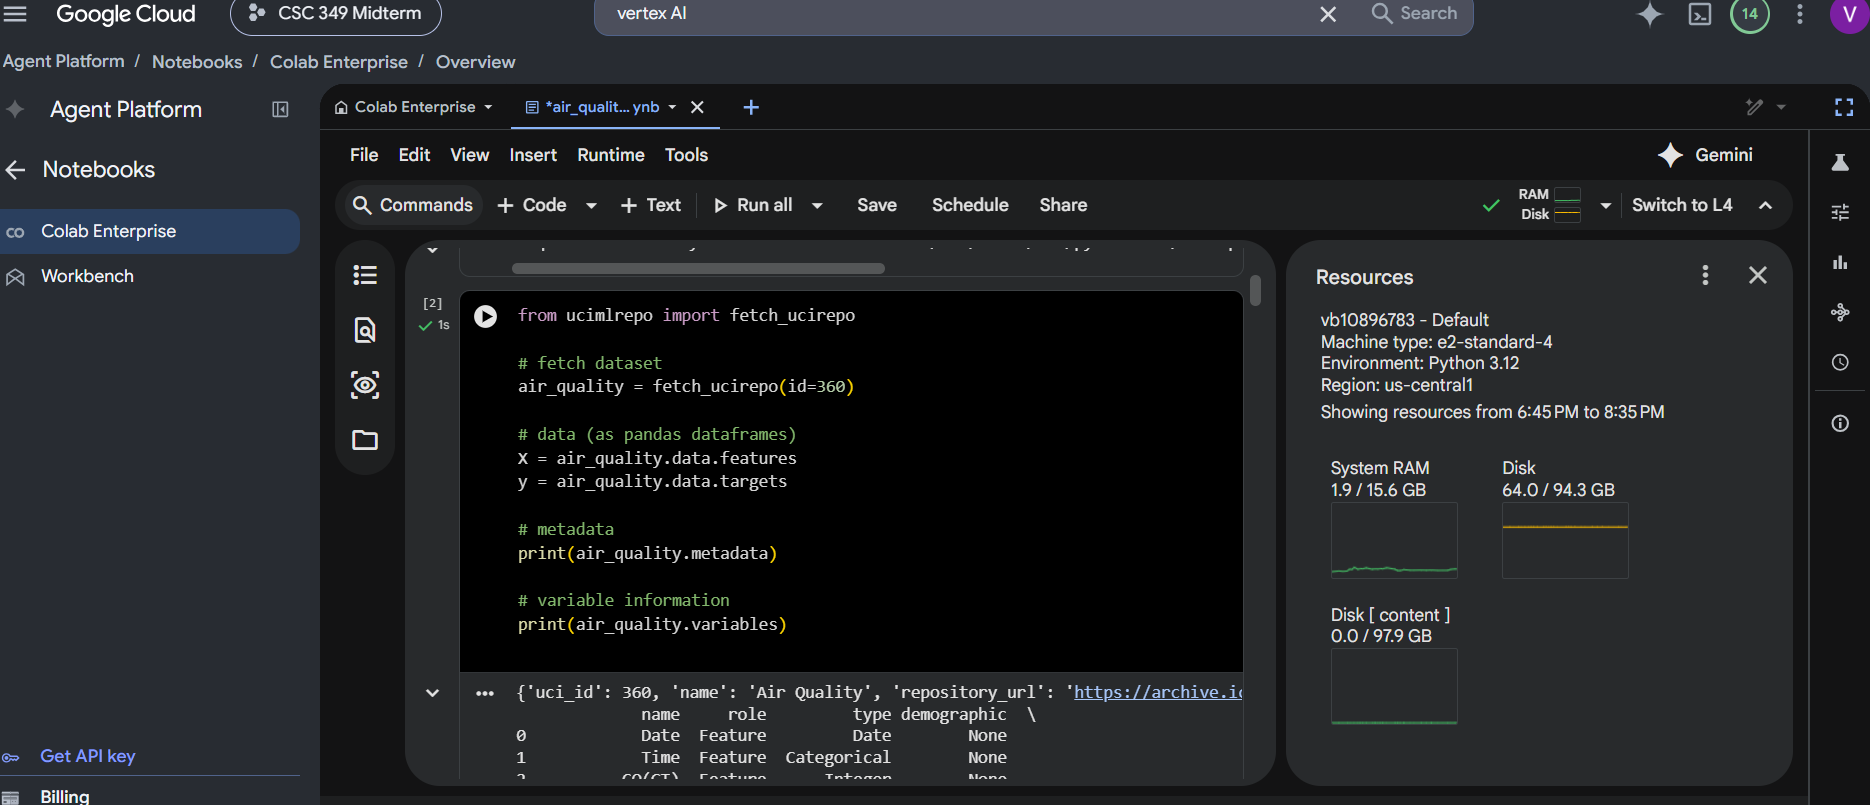

#2. Loading the dataset using ucimlrepo

In [1]:
%pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
air_quality = fetch_ucirepo(id=360)

# data (as pandas dataframes)
X = air_quality.data.features
y = air_quality.data.targets

# metadata
print(air_quality.metadata)

# variable information
print(air_quality.variables)


{'uci_id': 360, 'name': 'Air Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/360/air+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/360/data.csv', 'abstract': 'Contains the responses of a gas multisensor device deployed on the field in an Italian city. Hourly responses averages are recorded along with gas concentrations references from a certified analyzer. ', 'area': 'Computer Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 9358, 'num_features': 15, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Sun Mar 10 2024', 'dataset_doi': '10.24432/C59K5F', 'creators': ['Saverio Vito'], 'intro_paper': {'ID': 420, 'type': 'NATIVE', 'title': 'On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario', 'authors': 

#3. Inspecting data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder)

uci = air_quality.data.features.copy()
display(uci.head())
uci.info()
display(uci.describe())

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(5), int64(8), object(2)
memory usage: 1.1+ MB


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


#4. Missing values

In [4]:
uci = air_quality.data.features.copy()
uci = uci.replace(-200, np.nan)

display(uci.isna().sum())

uci = uci.dropna(subset=["CO(GT)"]).copy()

print("Remaining -200 targets:", (uci["CO(GT)"] == -200).sum())
print("CO range:", uci["CO(GT)"].min(), uci["CO(GT)"].max())

,0
Date,0
Time,0
CO(GT),1683
PT08.S1(CO),366
NMHC(GT),8443
C6H6(GT),366
PT08.S2(NMHC),366
NOx(GT),1639
PT08.S3(NOx),366
NO2(GT),1642


Remaining -200 targets: 0
CO range: 0.1 11.9


#5. ColumnTransformer and Pipeline

I used CO concentration as the target: Class 0 = Low (<= 1), Class 1 = Moderate (1 - 3), and Class 2 = High (> 3 mg/m³)

In [5]:
date = pd.to_datetime(uci["Date"], format="%m/%d/%Y", errors="coerce")

time = pd.to_datetime(uci["Time"].str.replace(".", ":", regex=False), format="%H:%M:%S",errors="coerce")

uci["month"] = date.dt.month.map(lambda x: str(int(x)) if pd.notna(x) else np.nan)

uci["hour"] = time.dt.hour.map(lambda x: str(int(x)) if pd.notna(x) else np.nan)

y_reg = uci["CO(GT)"]

y_class = pd.cut(y_reg,bins=[-np.inf, 1, 3, np.inf], labels=[0, 1, 2]).astype(int)

X = uci.drop(columns=["CO(GT)", "Date", "Time"])

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

(X_train, X_test,y_train, y_test,y_reg_train, y_reg_test) = train_test_split(
    X, y_class, y_reg,test_size=0.2,random_state=42,stratify=y_class)

def make_preprocessor(scaler):
    numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")),
        ("scaler", scaler)])

    categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore",sparse_output=False))])

    return ColumnTransformer([("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)])

#6. Training classification models

In [6]:
from time import perf_counter
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

scalers = {"Standard": StandardScaler(), "MinMax": MinMaxScaler()}

models = {
    "Logistic": LogisticRegression(solver="lbfgs", max_iter=1000),
    "Softmax": LogisticRegression(solver="lbfgs", max_iter=1000),
    "SGD log_loss": SGDClassifier(loss="log_loss", alpha=0.0001, learning_rate="optimal", max_iter=1000, tol=1e-3, random_state=42),
    "SGD hinge": SGDClassifier(loss="hinge", alpha=0.0001, learning_rate="optimal", max_iter=1000, tol=1e-3, random_state=42)}

results = []

for scaler_name, scaler in scalers.items():
    for model_name, model in models.items():

        if model_name == "Logistic":
            train_target = (y_train == 2).astype(int)
            test_target = (y_test == 2).astype(int)
        else:
            train_target = y_train
            test_target = y_test

        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(clone(scaler))),
            ("classifier", clone(model))
        ])

        start = perf_counter()
        pipeline.fit(X_train, train_target)
        fit_time = perf_counter() - start

        predictions = pipeline.predict(X_test)

        probability_loss = np.nan

        if hasattr(pipeline, "predict_proba"):
            probabilities = pipeline.predict_proba(X_test)
            probability_loss = log_loss(test_target, probabilities)

        results.append({
            "Scaler": scaler_name,
            "Model": model_name,
            "Accuracy": accuracy_score(test_target, predictions),
            "Macro F1": f1_score(test_target, predictions, average="macro", zero_division=0),
            "Log loss": probability_loss,
            "Fit seconds": fit_time,
            "Iterations": int(np.max(pipeline.named_steps["classifier"].n_iter_))})

classification_results = pd.DataFrame(results)
display(classification_results.round(4))

,Scaler,Model,Accuracy,Macro F1,Log loss,Fit seconds,Iterations
0,Standard,Logistic,0.9537,0.9327,0.1255,0.3214,43
1,Standard,Softmax,0.8762,0.8725,0.3339,2.8706,86
2,Standard,SGD log_loss,0.8782,0.8735,0.3464,0.4365,44
3,Standard,SGD hinge,0.8756,0.8718,NaN,0.3338,57
4,MinMax,Logistic,0.9505,0.9276,0.1323,0.2481,33
5,MinMax,Softmax,0.8697,0.8655,0.3409,2.6245,68
6,MinMax,SGD log_loss,0.8560,0.8483,0.4050,0.3364,35
7,MinMax,SGD hinge,0.8560,0.8462,NaN,0.2925,55


#7. Transition to regression tasks

In [7]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

models = {"Linear": LinearRegression()}

for alpha in [0.01, 0.1, 1, 10]:
    models[f"Ridge {alpha}"] = Ridge(alpha=alpha)
    models[f"Lasso {alpha}"] = Lasso(alpha=alpha, max_iter=10000)

results = []
coefficients = {}

for model_name, model in models.items():
    pipeline = Pipeline([("preprocessor", make_preprocessor(StandardScaler())), ("regressor", model)])

    pipeline.fit(X_train, y_reg_train)
    predictions = pipeline.predict(X_test)

    coef = pipeline.named_steps["regressor"].coef_
    feature_names = (pipeline.named_steps["preprocessor"].get_feature_names_out())

    coefficients[model_name] = pd.Series(coef, index=feature_names)

    results.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, predictions)),
        "R²": r2_score(y_reg_test, predictions),
        "Coefficient L2 norm": np.linalg.norm(coef),
        "Zero coefficients": np.isclose(coef, 0, atol=1e-8, rtol=0).sum()})

regression_results = pd.DataFrame(results)
coefficient_table = pd.DataFrame(coefficients)

display(regression_results.round(4))
display(coefficient_table.round(4))

,Model,RMSE,R²,Coefficient L2 norm,Zero coefficients
0,Linear,0.4694,0.8947,1.7982,0
1,Ridge 0.01,0.4694,0.8947,1.7980,0
2,Lasso 0.01,0.5012,0.8799,0.9129,30
3,Ridge 0.1,0.4694,0.8947,1.7959,0
4,Lasso 0.1,0.5534,0.8536,0.8740,43
5,Ridge 1,0.4694,0.8947,1.7756,0
6,Lasso 1,1.1843,0.3297,0.3059,47
7,Ridge 10,0.4697,0.8946,1.6157,0
8,Lasso 10,1.4465,-0.0000,0.0000,48


,Linear,Ridge 0.01,Lasso 0.01,Ridge 0.1,Lasso 0.1,Ridge 1,Lasso 1,Ridge 10,Lasso 10
num__PT08.S1(CO),0.1016,0.1016,0.1530,0.1018,0.1685,0.1041,0.0000,0.1225,0.0
num__NMHC(GT),0.0718,0.0718,0.0875,0.0718,0.0215,0.0721,0.0000,0.0741,0.0
num__C6H6(GT),0.7787,0.7786,0.5633,0.7775,0.7655,0.7666,0.3059,0.6809,0.0
num__PT08.S2(NMHC),-0.5723,-0.5721,0.0000,-0.5701,0.0000,-0.5510,0.0000,-0.3983,0.0
num__NOx(GT),0.5570,0.5570,0.5162,0.5570,0.3823,0.5574,0.0000,0.5592,0.0
num__PT08.S3(NOx),-0.0728,-0.0728,0.0086,-0.0725,-0.0000,-0.0697,-0.0000,-0.0468,-0.0
num__NO2(GT),0.0966,0.0966,0.1035,0.0966,0.0540,0.0962,0.0000,0.0942,0.0
num__PT08.S4(NO2),0.7398,0.7397,0.3146,0.7390,0.0000,0.7319,0.0000,0.6727,0.0
num__PT08.S5(O3),-0.0809,-0.0809,-0.0594,-0.0811,0.0000,-0.0836,0.0000,-0.1019,0.0
num__T,-0.1325,-0.1326,-0.0254,-0.1327,-0.0000,-0.1336,-0.0000,-0.1401,0.0


#8. Credit consumption

Billing and credit consumption takes up to a day to show up on my account. I'll upload it as soon as it's there.

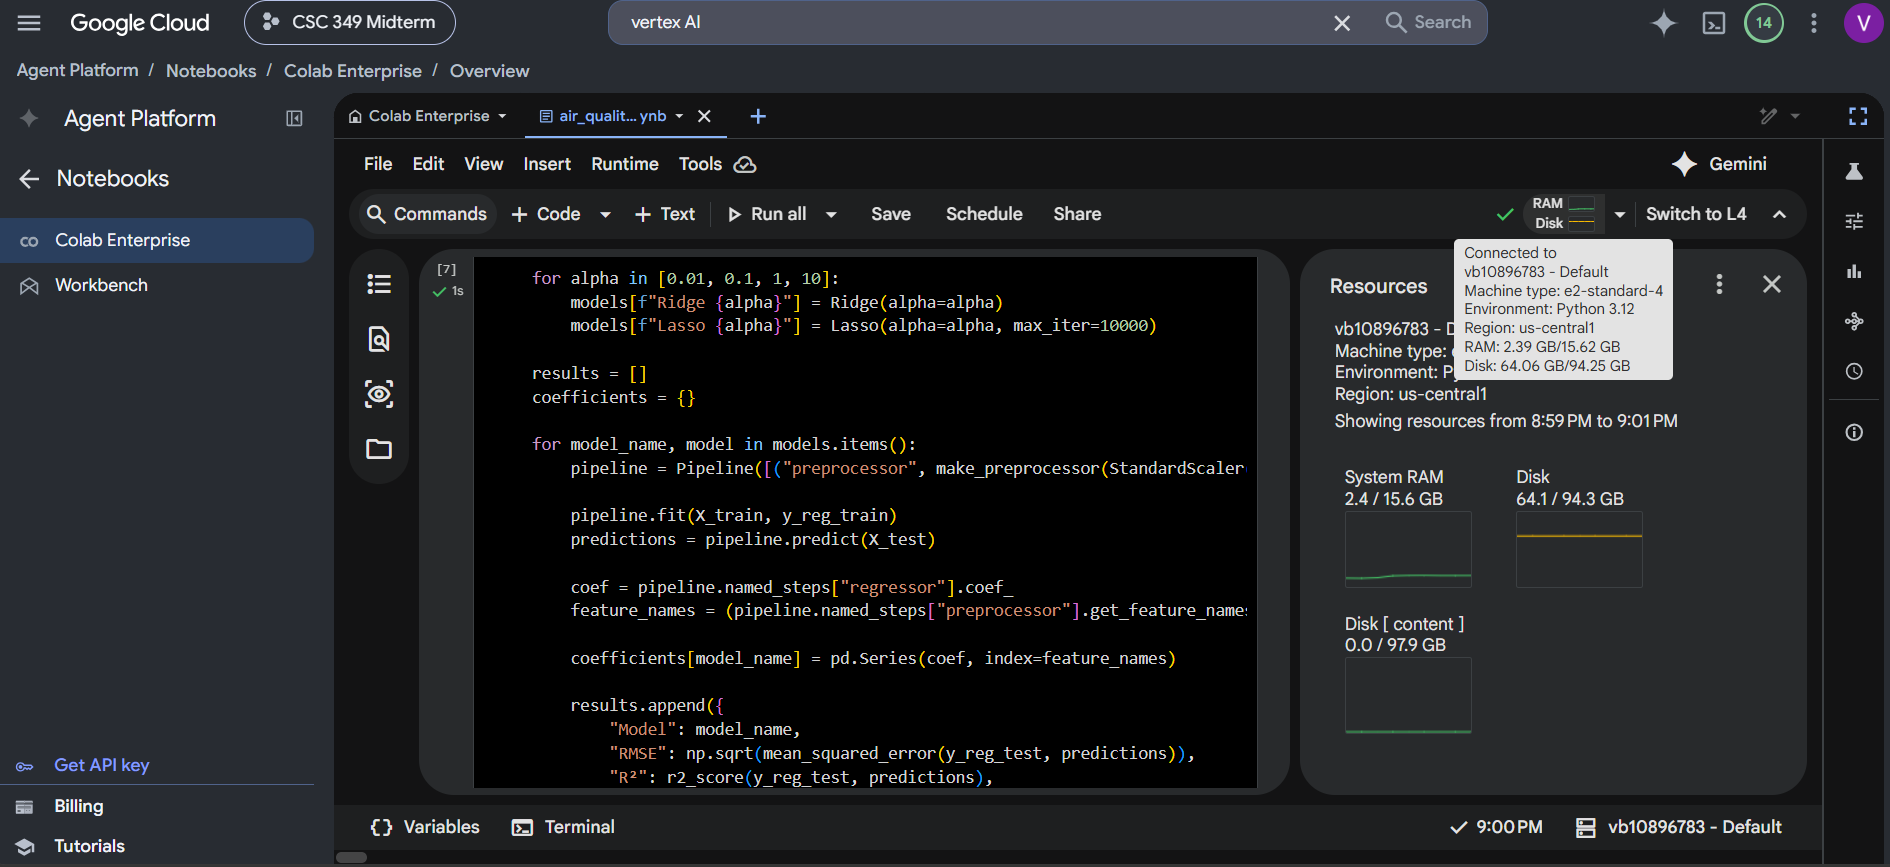